# Gradient ascent 2D

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sym

In [3]:
# Peaks function

def peaks(x,y):
    # Expand a 2d mesh
    x,y = np.meshgrid(x,y)

    z = 3*(1-x)**2 * np.exp(-(x**2)-(y+1)**2) \
        - 10*(x/5 - x**3 - y **5) * np.exp(-x**2-y**2) \
        -1/3 * np.exp(-(x+1)**2 - y**2)
    return z

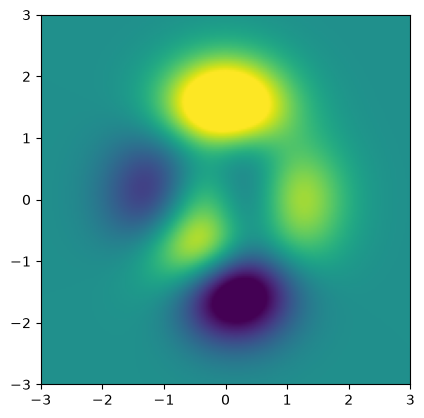

In [4]:
# Create landscape

x = np.linspace(-3,3,201)
y = np.linspace(-3,3,201)

z = peaks(x,y)


plt.imshow(z,extent=[x[0],x[-1],y[0],y[-1]], vmin=-5,vmax=5,origin='lower')
plt.show()

In [5]:
# Create derivative functions using sym

sx,sy = sym.symbols('sx,sy')

sz = 3*(1-sx)**2 * sym.exp(-(sx**2)-(sy+1)**2) \
        - 10*(sx/5 - sx**3 - sy **5) * sym.exp(-sx**2-sy**2) \
        -1/3 * sym.exp(-(sx+1)**2 - sy**2)

# Create functions from the sympy computed derivatives

df_x = sym.lambdify((sx,sy),sym.diff(sz,sx),'sympy')
df_y = sym.lambdify((sx,sy),sym.diff(sz,sy),'sympy')

df_x(1,1).evalf()

-1.07369833656079

[1.28569146287419 -0.00522665891893314]
[ 0.9508903  -0.55523819]


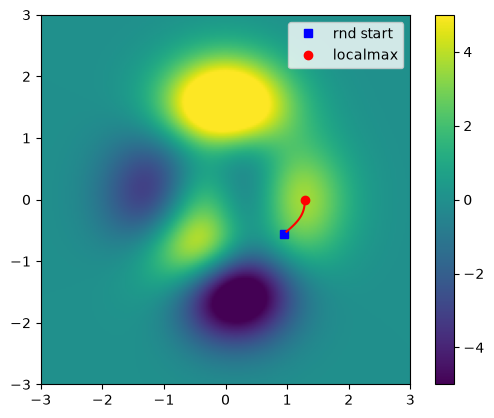

In [11]:
# Gradient descent algoritm

localmax = np.random.rand(2)*4-2
startpoint = localmax[:]

# Learning parameters
learning_rate = .01
training_epochs = 100

trajectory = np.zeros((training_epochs,2))

for i in range(training_epochs):
    grad = np.array([
        df_x(localmax[0],localmax[1]).evalf(),
        df_y(localmax[0],localmax[1]).evalf()
    ])

    localmax = localmax + learning_rate * grad
    trajectory[i:] = localmax

print(localmax)
print(startpoint)

# plot results

plt.imshow(z,extent=[x[0],x[-1],y[0],y[-1]], vmin=-5,vmax=5,origin='lower')
plt.plot(startpoint[0],startpoint[1],'bs')
plt.plot(localmax[0],localmax[1],'ro')
plt.plot(trajectory[:,0],trajectory[:,1],'r')
plt.legend(['rnd start','localmax'])
plt.colorbar()
plt.show()

[-0.00931758195995413 1.58136796293900]
[-0.00931758195995413 1.58136796293900]


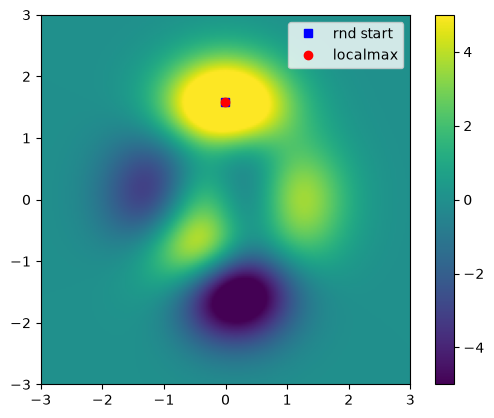

In [9]:
# Force initial starting guess

# Gradient descent algoritm

localmin = [0,31]
startpoint = localmax[:]

# Learning parameters
learning_rate = .01
training_epochs = 100

trajectory = np.zeros((training_epochs,2))

for i in range(training_epochs):
    grad = np.array([
        df_x(localmax[0],localmax[1]).evalf(),
        df_y(localmax[0],localmax[1]).evalf()
    ])

    localmax = localmax + learning_rate * grad
    trajectory[i:] = localmax

print(localmax)
print(startpoint)

# plot results

plt.imshow(z,extent=[x[0],x[-1],y[0],y[-1]], vmin=-5,vmax=5,origin='lower')
plt.plot(startpoint[0],startpoint[1],'bs')
plt.plot(localmax[0],localmax[1],'ro')
plt.plot(trajectory[:,0],trajectory[:,1],'r')
plt.legend(['rnd start','localmax'])
plt.colorbar()
plt.show()